<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/HIERARCHICAL_CLUSTERING_EXP8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load dataset

Download Mall_Customers.csv from the Kaggle link in your manual. Then run this cell and choose the file when the upload button appears.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

files.upload()   # select Mall_Customers.csv

data = pd.read_csv("Mall_Customers.csv")
print(data.shape)
data.head()

Saving Mall_Customers.csv to Mall_Customers.csv
(200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
import scipy.cluster.hierarchy as sch

# Ward linkage merges the closest clusters step by step
dendro = sch.dendrogram(sch.linkage(X, method="ward"))
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean distances")
plt.show()
# The longest vertical line not crossed by a horizontal line gives the best cut: 5 clusters

NameError: name 'X' is not defined

In [ ]:
print(data.columns)

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [ ]:
X = data[["Annual Income (k$)", "Spending Score (1-100)"]].values
print(X[:5])

[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


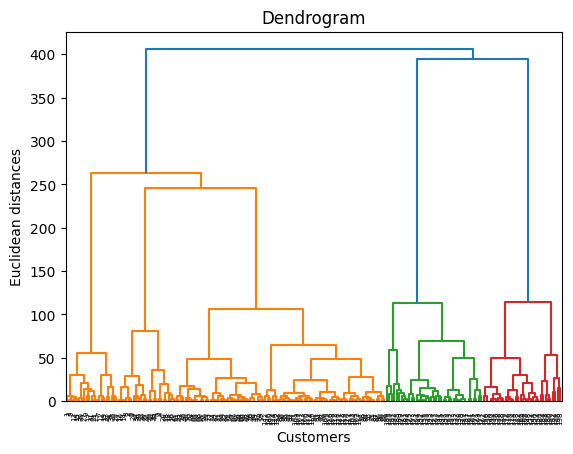

In [ ]:
import scipy.cluster.hierarchy as sch

dendro = sch.dendrogram(sch.linkage(X, method="ward"))
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean distances")
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Newer sklearn versions removed 'affinity', so it is not used here
hc = AgglomerativeClustering(n_clusters=5, linkage="ward")
y_hc = hc.fit_predict(X)
print(y_hc[:20])

[4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3]


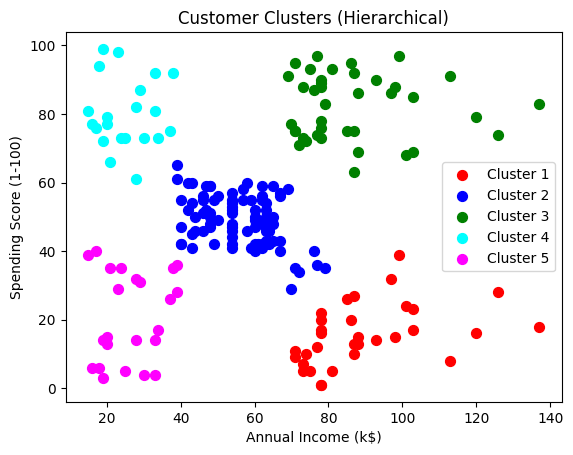

In [ ]:
colors = ["red", "blue", "green", "cyan", "magenta"]
for i in range(5):
    plt.scatter(X[y_hc == i, 0], X[y_hc == i, 1], s=50, c=colors[i], label=f"Cluster {i+1}")
plt.title("Customer Clusters (Hierarchical)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

results = []
for method in ["single", "complete", "average", "ward"]:
    labels = AgglomerativeClustering(n_clusters=5, linkage=method).fit_predict(X)
    results.append([method, round(silhouette_score(X, labels), 3)])

# Higher silhouette score = better clusters
pd.DataFrame(results, columns=["Linkage", "Silhouette score"])

,Linkage,Silhouette score
0,single,0.269
1,complete,0.553
2,average,0.479
3,ward,0.553


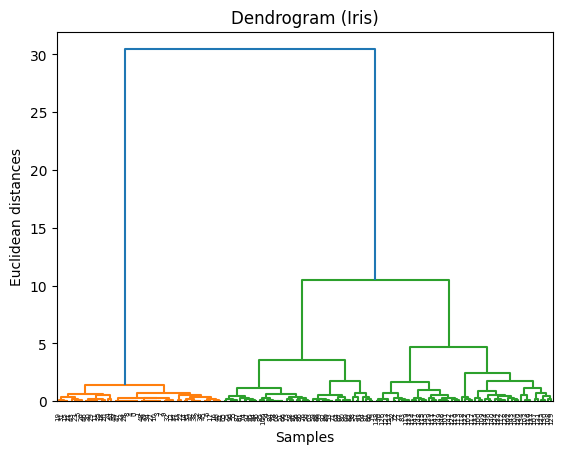

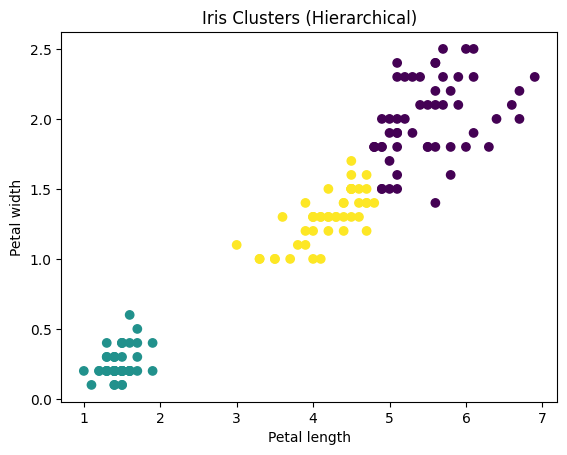

Silhouette score: 0.657


In [ ]:
from sklearn.datasets import load_iris

iris = load_iris()
X2 = iris.data[:, [2, 3]]   # petal length and petal width

# Dendrogram
sch.dendrogram(sch.linkage(X2, method="ward"))
plt.title("Dendrogram (Iris)")
plt.xlabel("Samples")
plt.ylabel("Euclidean distances")
plt.show()

# Clustering with 3 clusters (Iris has 3 species)
y2 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X2)

plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="viridis")
plt.title("Iris Clusters (Hierarchical)")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()

print("Silhouette score:", round(silhouette_score(X2, y2), 3))